# Beyond: the default definition is part of the PD, informative withdrawals and thin cohorts

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01, 02 and 07 of this topic (the PD by grade, the intervals and the IRB function)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- show on one agency's data that the definition of default is part of the PD: the same grade has two long-run PDs a factor of three apart under two pages of the same publication, and the portfolio risk weight moves with it;
- say how the sampling error of a PD compares with the effect of the definition;
- measure on rating paths of known truth how much informative withdrawals bias a PD under the three treatments in use, and why no matrix test sees it;
- measure exactly how often the interval of a thin grade contains its PD under three interval methods;
- state the claim BS-4 of the product, the evidence behind it and its limits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.regulatory import capital_requirement
from riskvalidation.transitions import intervals

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files of case C04 (ESMA CEREP, licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: S&P's long-run PDs by grade under CEREP's pages (`outputs.lra`), their gap (`outputs.definition_gap`), the cohort sizes and the committed risk weights (`impact`).
- `data/derived/C04/withdrawals.json`: a simulation study on rating paths of known truth (the generator of notebook 03) in which a share of the ratings is withdrawn at 6% a year, and more often just before default by a factor $1 + k$ for $k$ in 0, 1, 3, 9 (informative withdrawals); 200 seeded datasets per rung.
- `data/derived/C04/thin.json`: the exact coverage of three intervals at the generator's true PD for 50 to 1,000 obligors per grade, by enumerating the binomial counts.

**The three pages.** CEREP states that "no deterministic definition of a default event has been set up", so every PD names its page. `d2` is the default page: the distinct ratings counted as defaults over the page's own cohort. `d3` is its default events over the transition page's cohort. `d4` is the transition page's default column over the cohort less its withdrawals, the industry treatment. The next cell loads the files.

In [2]:
# Load the three artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, wd, thin = load("sp.json"), load("withdrawals.json"), load("thin.json")
out = sp["outputs"]
grades = out["grades"]
for label, doc in (("sp", sp), ("withdrawals", wd), ("thin", thin)):
    print(f"{label:12s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("grades:", grades)
print("attribution:", out["attribution"])

sp           baked by riskvalidation 0.4.3 | installed 0.9.0
withdrawals  baked by riskvalidation 0.4.3 | installed 0.9.0
thin         baked by riskvalidation 0.4.3 | installed 0.9.0
grades: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C']
attribution: Source: ESMA CEREP; tables transformed by Contraste


## Method

### Step 1: the definition is part of the PD

The long-run average default rate (EBA/GL/2017/16, paragraph 84) is the mean of the yearly rates over the cohorts where the grade has ratings, as in notebook 01. The next cell prints it for each grade under the default page (`d2`), the default events on the transition cohort (`d3`) and the transition page (`d4`), the ratio of `d4` to `d2` pooled over the cohorts where both exist (`definition_gap`), and the Jeffreys interval of the `d4` rate, which is the sampling uncertainty of the number. Then it asks how many half-widths of that interval the definition moves the CCC to C grade.

In [3]:
# Long-run PD of each grade under the three definitions, the committed gap, and the definition's effect against the sampling interval
lra = {d: np.array(out["lra"][d]["rate"], dtype=float) for d in ("d2", "d3", "d4")}
gap = out["definition_gap"]
print(f"{'grade':8s}{'d2 (%)':>10s}{'d3 (%)':>10s}{'d4 (%)':>10s}{'d4 / d2':>10s}{'d3 / d2':>10s}")
for g in range(7):
    r4 = gap["d4_over_d2"][g]
    r3 = gap["d3_over_d2"][g]
    print(f"{grades[g]:8s}{100 * lra['d2'][g]:10.4f}{100 * lra['d3'][g]:10.4f}{100 * lra['d4'][g]:10.4f}{('-' if r4 is None else format(r4, '.3f')):>10s}{('-' if r3 is None else format(r3, '.3f')):>10s}")
low, high = out["lra"]["d4"]["jeffreys"]["lower"][6], out["lra"]["d4"]["jeffreys"]["upper"][6]
half_width = (high - low) / 2
print("CCC to C, d4: Jeffreys interval (%):", round(100 * low, 3), "to", round(100 * high, 3), "| half-width (points):", round(100 * half_width, 3))
print("CCC to C: d2 minus d4 (points):", round(100 * (lra["d2"][6] - lra["d4"][6]), 3), "| in half-widths of the d4 interval:", round((lra["d2"][6] - lra["d4"][6]) / half_width, 1))
yearly = np.array([c["counts"][6][7] / (c["size"][6] - c["withdrawn"][6]) for c in out["cohorts"]])   # the d4 rate of CCC to C in each cohort
cycle_se = yearly.std(ddof=1) / np.sqrt(len(yearly))
print("CCC to C, d4:", len(yearly), "yearly rates | their mean equals the committed rate:", bool(np.isclose(yearly.mean(), lra["d4"][6])))
print("CCC to C, d4: standard error of that mean across the years (points):", round(100 * cycle_se, 3), "| d2 minus d4 in those standard errors:", round((lra["d2"][6] - lra["d4"][6]) / cycle_se, 1))
print("d4 / d2 for CCC to C and B:", round(gap["d4_over_d2"][6], 3), round(gap["d4_over_d2"][5], 3))

grade       d2 (%)    d3 (%)    d4 (%)   d4 / d2   d3 / d2
AAA         0.0000    0.0000    0.0000         -         -
AA          0.0093    0.0093    0.0049     0.529     1.000
A           0.0350    0.0350    0.0305     0.850     1.000
BBB         0.1134    0.1134    0.0793     0.703     1.000
BB          0.5299    0.5412    0.3363     0.629     1.015
B           2.9574    3.0422    1.3301     0.446     1.045
CCC-C      26.6369   27.5771    8.6084     0.294     1.041
CCC to C, d4: Jeffreys interval (%): 7.226 to 8.974 | half-width (points): 0.874
CCC to C: d2 minus d4 (points): 18.029 | in half-widths of the d4 interval: 20.6
CCC to C, d4: 26 yearly rates | their mean equals the committed rate: True
CCC to C, d4: standard error of that mean across the years (points): 1.208 | d2 minus d4 in those standard errors: 14.9
d4 / d2 for CCC to C and B: 0.294 0.446


A PD is a number with a sampling error and a definition. Here the definition moves the CCC to C grade by 20.6 half-widths of the Jeffreys interval of the `d4` rate. That interval treats the defaults as independent, but yearly default rates move with the credit cycle, so the cell also prints the standard error of the mean of the 26 yearly rates, the fairer yardstick for a long-run average (Schuermann and Hanson, 2004, correct for this correlation with a design effect). The definition effect is many times larger than either yardstick, so both numbers are estimated well enough for the definition to dominate. What the definition does to capital follows. The cell takes the grade mix of the 26 cohorts and the long-run PDs under `d2` and `d4`, and computes the average Basel III corporate risk weight with the engine (maturity 2.5, PD floor 0.05%; the function is CRE31.5, the parameters CRE32, https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27) as in notebook 07. The LGD of 45% is the foundation-IRB value for senior unsecured claims on financial institutions (CRE32.6; other corporates have 40%) and it is combined with the non-financial corporate correlation, without the 1.25 multiplier of CRE31.7. That is the case's assumption and it sets the level of the risk weights, not the comparison: the risk weight is proportional to the LGD, so the ratio of `d4` to `d2` does not depend on it.

In [4]:
# Average IRB risk weight of the cohort mix under d2 and d4, against the committed risk weights
irb = out["irb"]
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
risk_weight = lambda pd: capital_requirement(irb["asset_class"], float(pd), irb["lgd"], maturity=irb["maturity"], regime=irb["regime"]).risk_weight
portfolio = {d: float(np.sum(mix * np.array([risk_weight(p) for p in lra[d]]))) for d in ("d2", "d4")}
for d in ("d2", "d4"):
    print(f"{d}: average risk weight", round(100 * portfolio[d], 2), "% | committed", round(100 * sp["impact"]["rw_" + d]["value"], 2), "%")
print("equal to the committed risk weights:", all(np.isclose(portfolio[d], sp["impact"]["rw_" + d]["value"], atol=1e-8) for d in portfolio))
print("risk weight moves by", round(100 * (portfolio["d4"] / portfolio["d2"] - 1), 1), "% from d2 to d4")
print("CCC to C long-run PD under d2 and d4 (%), committed impact:", round(100 * sp["impact"]["lra_d2_ccc_c"]["value"], 2), round(100 * sp["impact"]["lra_d4_ccc_c"]["value"], 2))

d2: average risk weight 57.97 % | committed 57.97 %
d4: average risk weight 47.45 % | committed 47.45 %
equal to the committed risk weights: True
risk weight moves by -18.1 % from d2 to d4
CCC to C long-run PD under d2 and d4 (%), committed impact: 26.64 8.61


### Step 2: informative withdrawals

A rating is withdrawn when the agency stops rating the borrower. The industry treatment (CEREP's transition page) treats a withdrawal as non-informative: it removes it and divides by what remains (Schuermann and Hanson, 2004, footnote 4). EBA/GL/2017/16, paragraph 76, asks instead to keep closed obligations and follow them. If borrowers in trouble are withdrawn more often, both are biased, and a validator cannot see it in the matrix. The committed study draws rating paths from the generator of notebook 03, withdraws 6% a year, and withdraws $1 + k$ times more often in the year before default, for $k$ = 0 (non-informative), 1, 3 and 9. For each rung it computes, over 200 datasets, the one-year PD with withdrawals **removed**, **kept** unfollowed as an absorbing state, **followed** (each year's cohort as observed, with its end read on the latent path, so a rating withdrawn within the year that defaults by its end counts as a default) and the **latent** chain's own PD (every obligor followed every year), against the truth. The next cell prints the relative bias of each for B and CCC to C, with the Monte Carlo error.

In [5]:
# Relative bias of the four PDs for B and CCC to C at each informative-withdrawal rung, with the Monte Carlo error
rungs = wd["outputs"]["rungs"]
treatments = (("pd_removed", "removed"), ("pd_kept", "kept"), ("pd_followed", "followed"), ("pd_latent", "latent chain"))
print("datasets per rung:", rungs[0]["pd_removed"]["n"][0], "| withdrawal rate a year:", rungs[0]["withdrawal_rate"], "| window before default (years):", rungs[0]["window"])
for g in (5, 6):
    print(f"grade {grades[g]} | true PD (%): {100 * rungs[0]['pd_removed']['truth'][g]:.4f}")
    print(f"{'k':>6s}" + "".join(f"{label:>22s}" for _, label in treatments) + f"{'withdrawn share':>22s}")
    for r in rungs:
        cells = "".join(f"{r[key]['bias'][g] / r[key]['truth'][g]:+13.3f} ({r[key]['bias_mcse'][g] / r[key]['truth'][g]:.3f})" for key, _ in treatments)
        print(f"{r['value']:6.0f}{cells}{r['withdrawn_share']['mean'][g]:22.3f}")

datasets per rung: 200 | withdrawal rate a year: 0.06 | window before default (years): 1.0
grade B | true PD (%): 1.1731
     k               removed                  kept              followed          latent chain       withdrawn share
     0       +0.024 (0.010)       -0.036 (0.009)       -0.005 (0.009)       -0.004 (0.009)                 0.058
     1       -0.026 (0.009)       -0.083 (0.009)       -0.024 (0.009)       +0.000 (0.008)                 0.058
     3       -0.125 (0.009)       -0.177 (0.008)       -0.062 (0.008)       -0.007 (0.008)                 0.060
     9       -0.339 (0.008)       -0.381 (0.007)       -0.152 (0.008)       +0.008 (0.008)                 0.063
grade CCC-C | true PD (%): 8.0618
     k               removed                  kept              followed          latent chain       withdrawn share
     0       +0.032 (0.007)       -0.025 (0.007)       +0.002 (0.007)       +0.001 (0.007)                 0.055
     1       -0.022 (0.007)       -0.080 (0.00

At $k = 9$, the strongest rung, removing the withdrawn ratings understates the PD of B by 34% and following them as paragraph 76 asks still understates it by 15%; the latent chain, which sees everyone, is unbiased. Each cell is the relative bias with its Monte Carlo standard error in brackets. At $k = 0$ the removed and kept treatments already carry a small bias (+0.024 and -0.036 for B, with Monte Carlo errors of 0.010 and 0.009), the kept one understating by construction because it treats a withdrawal as an absorbing state; the bias grows with $k$, so most of the 34% and 15% at $k = 9$ comes from the information in the withdrawals. The next question is whether the tests a validator has on the matrix would notice. The committed study runs the time-homogeneity test across the five annual matrices and the last year's counts against the exact matrix, at each rung.

In [6]:
# The rejection rates at 5% of the two matrix tests at each rung, from the committed study
sims = wd["outputs"]["simulations"]
print(f"{'k':>6s}{'homogeneity across years':>34s}{'last year vs the exact matrix':>40s}")
for r in rungs:
    h = next(s for s in sims if s["test_id"] == "rating.time_homogeneity" and s["rung"] == r["value"])["rates"]["p<0.05"]
    m = next(s for s in sims if s["test_id"] == "rating.matrix_reference" and s["rung"] == r["value"])["rates"]["p<0.05"]
    print(f"{r['value']:6.0f}{h['rate']:34.3f}{m['rate']:40.3f}")
print("datasets per row:", sims[0]["n_rep"], "| nominal level: 0.05")

     k          homogeneity across years           last year vs the exact matrix
     0                             0.025                                   0.000
     1                             0.040                                   0.000
     3                             0.015                                   0.000
     9                             0.040                                   0.010
datasets per row: 200 | nominal level: 0.05


Both tests reject at or below their nominal 5% at every rung, including $k = 9$ (4% and 1%), where the bias is a third of the PD: the matrix of the ratings that are still there passes as a Markov matrix, and the missing information is exactly what no test on it can see.

### Step 3: thin grades

Notebook 02 showed that the Wald interval of a grade with no observed default has width zero. How often does each interval contain the true PD when the grade is thin? The coverage of an interval method for $n$ obligors with true PD $p$ is exact: add the binomial probability of every default count whose interval contains $p$. The engine's `exact_coverage` does it, and the committed `thin.json` holds the results for the generator's true one-year PDs and 50 to 1,000 obligors per grade. The next cell reads them, and checks one by calling the engine for AAA with 50 obligors.

In [7]:
# Read the exact coverage of the three intervals for the thin grades and check one value with the engine
thin_out = thin["outputs"]
true_pd = np.array(thin_out["generator"]["pd_1y"])
ladder = thin_out["ladder"]["values"]
methods = {"wald": "Wald", "agresti_coull": "Agresti-Coull", "jeffreys": "Jeffreys"}
print("true one-year PD (%):", " ".join(f"{grades[g]} {100 * true_pd[g]:.4f}" for g in range(3)))
print(f"{'obligors per grade':>24s}" + "".join(f"{label + ' ' + grades[g]:>18s}" for label in methods.values() for g in (0, 1, 2)))
for r in thin_out["rungs"]:
    print(f"{r['value']:24d}" + "".join(f"{r['coverage'][m][g]:18.4f}" for m in methods for g in (0, 1, 2)))
live = intervals.exact_coverage("wald", 50, true_pd[0], level=0.95)
first = thin_out["rungs"][0]
print("engine, Wald, 50 obligors, AAA:", round(float(live["coverage"]), 6), "| committed:", round(first["coverage"]["wald"][0], 6), "| equal:", bool(np.isclose(live["coverage"], first["coverage"]["wald"][0], atol=1e-8)))
print("nominal level: 0.95")

true one-year PD (%): AAA 0.0066 AA 0.0049 A 0.0288
      obligors per grade          Wald AAA           Wald AA            Wald A Agresti-Coull AAA  Agresti-Coull AA   Agresti-Coull A      Jeffreys AAA       Jeffreys AA        Jeffreys A
                      50            0.0033            0.0025            0.0143            1.0000            1.0000            0.9999            0.9967            0.9975            0.9857
                     100            0.0065            0.0049            0.0284            1.0000            1.0000            0.9996            0.9935            0.9951            0.9716
                     200            0.0130            0.0098            0.0561            0.9999            1.0000            0.9984            0.9870            0.9902            0.9439
                     500            0.0323            0.0243            0.1343            0.9995            0.9997            0.9996            0.9677            0.9757            0.9906
             

## State of the art

### The practice this goes beyond

- **The definition.** ESMA's CEREP publication states that no deterministic definition of a default event has been set up for it, and the cohort and duration estimators of the literature take the agencies' tables as given (Schuermann and Hanson, 2004; the research dossier 13, sections 4 and 5). A PD from a CEREP table is therefore read as a number, with its sampling error, and the definition behind it is not part of the estimate.
- **Withdrawals.** The industry removes them (Schuermann and Hanson, footnote 4), EBA paragraph 76 asks to keep and follow them; the practice discusses the choice and does not measure the bias of each against a truth.
- **Thin grades.** Schuermann and Hanson use the Wald and Agresti-Coull intervals for PDs by grade, with a design-effect correction for correlation; Brown, Cai and DasGupta (2001) study their coverage for a binomial proportion in general. The coverage of each at the PDs and sizes of a rating scale is the question the practice leaves.

The notebook measures each of the three on the same agency and on a generator of known truth.

## Beyond the state of the art

### Claim BS-4: the default definition as part of the PD, informative withdrawals and thin grades

**What Contraste adds.** The same agency's long-run PD of the CCC to C grade is 26.64% under the CEREP default page and 8.61% under the transition page, and the IRB risk weight of the cohort mix moves from 58.0% to 47.5% with the definition; informative withdrawals and thin grades are measured on rating paths of known truth. The next cell lists each statement with the value this notebook read from the committed files, so the claim can be re-checked statement by statement.

In [8]:
# Each statement of the claim with the value read from the committed files
k9 = rungs[-1]
statements = [
    ("CCC to C long-run PD, default page (d2), %", 100 * lra["d2"][6], "C04/sp.json outputs.lra.d2"),
    ("CCC to C long-run PD, transition page (d4), %", 100 * lra["d4"][6], "C04/sp.json outputs.lra.d4"),
    ("IRB risk weight of the cohort mix under d2, %", 100 * portfolio["d2"], "C04/sp.json impact.rw_d2"),
    ("IRB risk weight of the cohort mix under d4, %", 100 * portfolio["d4"], "C04/sp.json impact.rw_d4"),
    ("B: relative bias of the PD, withdrawals removed, k = 9, %", 100 * k9["pd_removed"]["bias"][5] / k9["pd_removed"]["truth"][5], "C04/withdrawals.json rungs[k=9].pd_removed"),
    ("B: relative bias of the PD, withdrawals followed, k = 9, %", 100 * k9["pd_followed"]["bias"][5] / k9["pd_followed"]["truth"][5], "C04/withdrawals.json rungs[k=9].pd_followed"),
    ("AAA: share of 50-obligor samples whose Wald interval contains the PD, %", 100 * thin_out["rungs"][0]["coverage"]["wald"][0], "C04/thin.json rungs[n=50].coverage.wald"),
    ("AAA: the same, Jeffreys interval, %", 100 * thin_out["rungs"][0]["coverage"]["jeffreys"][0], "C04/thin.json rungs[n=50].coverage.jeffreys"),
]
for text, value, source in statements:
    print(f"{value:9.3f}  {text}  [{source}]")

   26.637  CCC to C long-run PD, default page (d2), %  [C04/sp.json outputs.lra.d2]
    8.608  CCC to C long-run PD, transition page (d4), %  [C04/sp.json outputs.lra.d4]
   57.969  IRB risk weight of the cohort mix under d2, %  [C04/sp.json impact.rw_d2]
   47.454  IRB risk weight of the cohort mix under d4, %  [C04/sp.json impact.rw_d4]
  -33.879  B: relative bias of the PD, withdrawals removed, k = 9, %  [C04/withdrawals.json rungs[k=9].pd_removed]
  -15.231  B: relative bias of the PD, withdrawals followed, k = 9, %  [C04/withdrawals.json rungs[k=9].pd_followed]
    0.328  AAA: share of 50-obligor samples whose Wald interval contains the PD, %  [C04/thin.json rungs[n=50].coverage.wald]
   99.672  AAA: the same, Jeffreys interval, %  [C04/thin.json rungs[n=50].coverage.jeffreys]


**Limits of the claim.** The definition gap is one agency's (S&P, EU entity, corporate long-term) and compares two pages of one publication that also count different cohorts (the artifact records the cohort difference as a finding); it says the definition matters, not which page is right. Informative withdrawals are planted in a simulation: the study shows what they would do and that no matrix test sees it, not that CEREP's withdrawals are informative. The thin-grade coverage is exact for the generator's PDs and sizes, a rating scale with these grade PDs. The claim is demonstrated by this notebook and the three files above, and is not stated beyond them.

The last figure draws the long-run PD of each grade under the three pages, and the coverage of the Wald and Jeffreys intervals of AAA against the number of obligors.

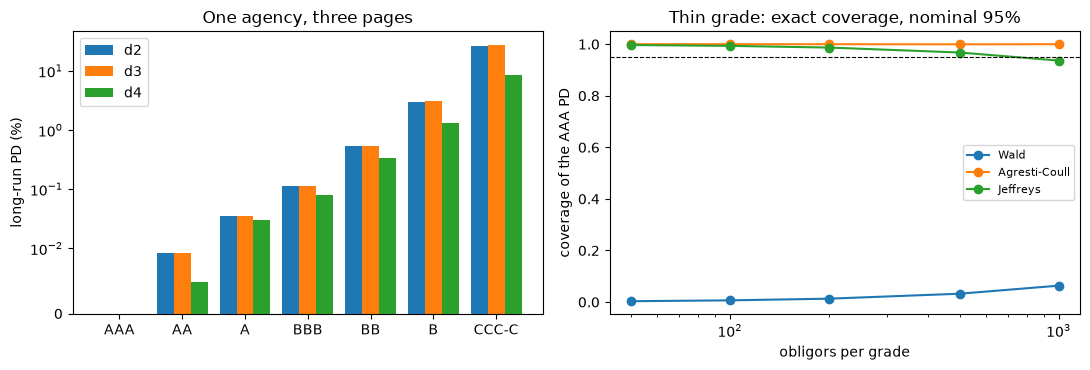

In [9]:
# Draw the long-run PD by page and the coverage of the AAA intervals against the sample size
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
width = 0.27
for k, d in enumerate(("d2", "d3", "d4")):
    left.bar(np.arange(7) + (k - 1) * width, 100 * lra[d], width, label=d)
left.set_yscale("symlog", linthresh=0.01)
left.set_xticks(range(7))
left.set_xticklabels(grades)
left.set_ylabel("long-run PD (%)")
left.set_title("One agency, three pages")
left.legend()
sizes = [r["value"] for r in thin_out["rungs"]]
for m, label in methods.items():
    right.plot(sizes, [r["coverage"][m][0] for r in thin_out["rungs"]], marker="o", label=label)
right.axhline(0.95, color="black", linestyle="--", linewidth=0.8)
right.set_xscale("log")
right.set_xlabel("obligors per grade")
right.set_ylabel("coverage of the AAA PD")
right.set_title("Thin grade: exact coverage, nominal 95%")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The definition is part of the PD.** Under the default page the long-run PD of CCC to C is 26.64% and under the transition page 8.61%, a ratio of 0.294; for B it is 2.96% against 1.33% (0.446), and the ratios run from 0.53 (AA) to 0.85 (A) in the grades between. The default events on the transition cohort (`d3`) are within 5% of the default page. The difference, 18.0 points, is 20.6 half-widths of the Jeffreys interval of the `d4` rate (7.23% to 8.97%) and 14.9 standard errors of the mean of its 26 yearly rates (1.21 points): sampling, even with the yearly rates' correlation with the cycle, does not come near it.
- **It moves capital.** The average Basel III corporate risk weight of the cohort mix is 57.97% with the default-page PDs and 47.45% with the transition-page PDs, 18.1% lower; both equal the committed values.
- **Informative withdrawals.** With withdrawals 10 times as likely in the year before default (`k = 9`), removing the withdrawn ratings understates the PD of B by 33.9% (Monte Carlo error 0.8 points) and of CCC to C by 33.1%; keeping them unfollowed by 38.1% and 38.5%; following them as EBA paragraph 76 asks by 15.2% and 17.7%; the latent chain is unbiased (+0.8% and +0.1%). At `k = 0` removed and kept are already off by +2.4% and -3.6% for B (Monte Carlo errors 1.0 and 0.9 points), and the bias grows with `k`. The time-homogeneity test rejects 2.5% to 4% of the datasets at 5% at every rung and the last-year test 0% to 1%: no matrix test sees the bias.
- **Thin grades.** With 50 obligors per grade the Wald interval contains the true PD of AAA in 0.33% of the samples (AA 0.25%, A 1.4%) and still in only 6.4% with 1,000 obligors (AA 4.8%, A 25.1%); the Agresti-Coull interval contains it in at least 99.95% of the samples for AAA and the Jeffreys interval in 99.7% at 50 obligors and 93.6% at 1,000 (nominal 95%). The engine's exact coverage equals the committed value.
- **The claim.** The eight statements of the claim BS-4 are listed with the values read from the committed files.

What this notebook does not show: that the withdrawals of CEREP are informative (they are planted in the simulation), or which page of CEREP is the right definition (the claim is that the choice matters and is not in the estimate).

## Summary

- The same agency's long-run PD of the CCC to C grade is 26.64% or 8.61% according to the page of CEREP it is read from, and the risk weight of the cohort mix moves 18%; the definition is part of the PD and not in its confidence interval.
- Informative withdrawals understate a PD by a third when removed and by about a sixth when followed, and no matrix test sees it.
- The Wald interval of a thin grade almost never contains its PD; the Jeffreys interval does, and the Agresti-Coull one over-covers.
- The claim BS-4 is stated only as far as these committed files and this notebook go.

**What to try next.** Rerun the withdrawal table for another grade and look at where the three treatments diverge; then read notebook 11 on the reconciliations.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions, with its help file ESMA65-8-10634 (sections 4.2 to 4.4 on the pages and the statement on the definition of default). https://registers.esma.europa.eu/cerep-publication/
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, footnote 4 (withdrawals) and section 3 (intervals). https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraphs 73, 76, 84 and 86.